In [26]:
import json
from datetime import date, datetime
import matplotlib.pyplot as plt
import seaborn as sns

import polars as pl
import yaml

from common import read_day


with open("../config.yaml", "r") as fp:
    config = yaml.safe_load(fp)

In [ ]:
sep9 = read_day(date(2025, 9, 9), config["dirs"]["pickwell"])
sep9 = sep9.with_columns(pl.from_epoch(pl.col("timestamp"), time_unit="s"))

In [ ]:
sep9_by_min = (
    sep9.sort("timestamp")
    .group_by_dynamic("timestamp", every="1m", closed="right")
    .agg(pl.col("device_aid_hashed").count())
    .sort("timestamp")
    .rename({"device_aid_hashed": "count"})
)

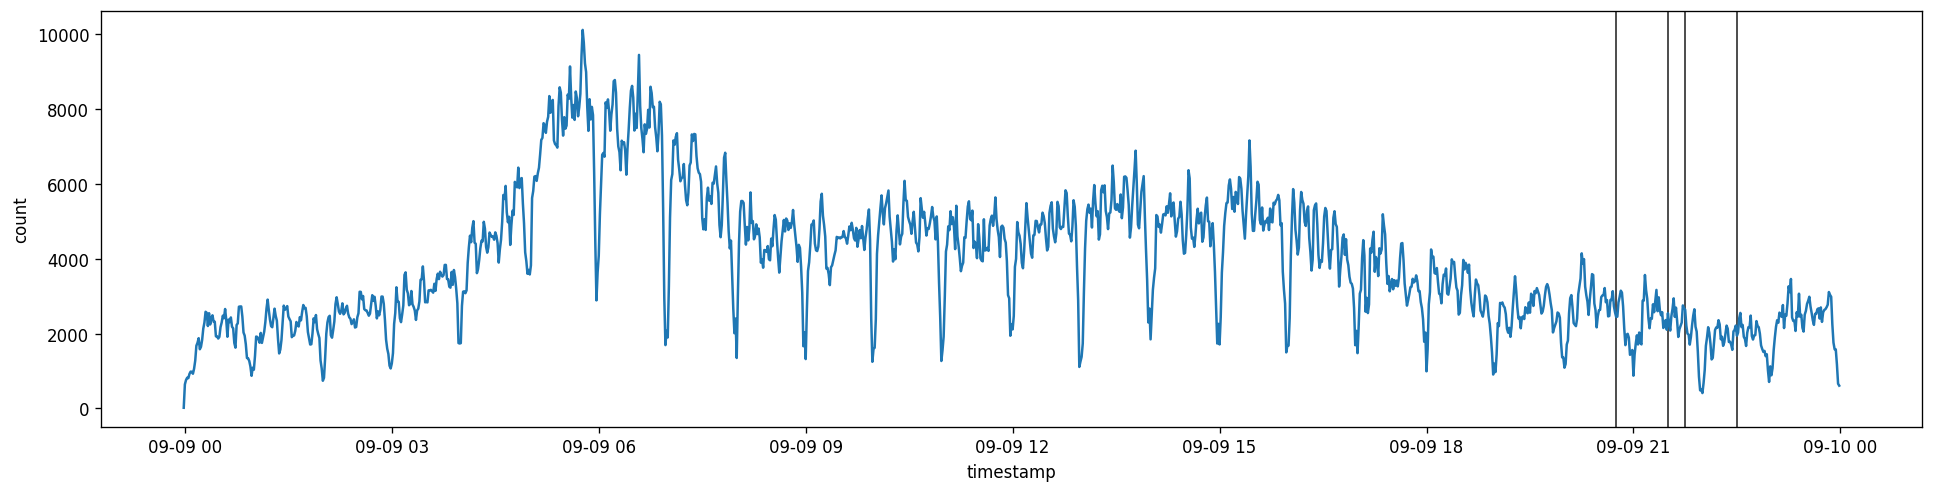

In [ ]:
fig, ax = plt.subplots(layout="constrained", figsize=(16, 4), dpi=120)
sns.lineplot(
    data=sep9_by_min,
    x="timestamp",
    y="count",
    ax=ax,
)
ax.axvline(
    datetime(2025, 9, 9, 20, 45), linestyle="solid", lw=1, color="#2d2d2d", zorder=1
)
ax.axvline(
    datetime(2025, 9, 9, 21, 30), linestyle="solid", lw=1, color="#2d2d2d", zorder=1
)
ax.axvline(
    datetime(2025, 9, 9, 21, 45), linestyle="solid", lw=1, color="#2d2d2d", zorder=1
)
ax.axvline(
    datetime(2025, 9, 9, 22, 30), linestyle="solid", lw=1, color="#2d2d2d", zorder=1
)